# REMNET · Stage 3 · Section 2 — Fully Automated Dataset Screening (Kaggle CPU)

This version **requires no human visual-review decisions**. It uses the established automatic KaggleHub download logic, validates the locked Stage 2 manifest, excludes exact byte-matches and within-external copies, screens cross-dataset and within-external pHash pairs, then performs independent automated pixel/structural examinations (decoded pixels, SSIM, RGB MAE, correlation, ORB/RANSAC where available) of every suspected pair.

**Conservative rule:** every external image appearing in *any* pHash candidate pair is excluded from the final automated-screened evaluation cohort, irrespective of its automated similarity score. That rule eliminates the need to guess whether an ambiguous pair is a true duplicate. No original image is changed or deleted.

The output **`Section2_Final_Automated_Screened_Six_Class_Manifest.csv`** is locked only when all machine-verifiable requirements pass, including examination coverage and the original Stage 2 class mapping. The same fingerprinted subset must be used for **all four model configurations and five seeds**. It is a reproducible **automated-screened** cohort, not a human-adjudicated dataset or proof of independent image collection provenance.

**Resources:** CPU-only. No REMNET training, inference, or CodeCarbon. Kaggle Internet may be required for dataset download. The Stage 2 authoritative CSV is included in the companion ZIP and can be attached using Kaggle Add Input.


In [1]:
# 1 — Fixed dataset definitions and audit settings
from pathlib import Path
from collections import Counter, defaultdict, OrderedDict
import os, sys, csv, json, hashlib, zipfile, subprocess, importlib, datetime, math, re
from PIL import Image, ImageOps, ImageDraw, ImageFont
import numpy as np

EXTERNAL_DATASET_HANDLE = 'sumn2u/garbage-classification-v2'
EXTERNAL_DATASET_VERSION = '12'   # specifically requested version; fallback is marked unverified
ORIGINAL_DATASET_HANDLE = 'saumyamohandas/garbage-classification-image-dataset'
EXTERNAL_DATASET_PATHS = [
    '/kaggle/input/datasets/sumn2u/garbage-classification-v2',
    '/kaggle/input/garbage-classification-v2',
]
ORIGINAL_DATASET_PATHS = [
    '/kaggle/input/datasets/saumyamohandas/garbage-classification-image-dataset',
    '/kaggle/input/garbage-classification-image-dataset',
]
KEEP = ('cardboard','glass','metal','paper','plastic','trash')
EXCLUDE = ('battery','biological','clothes','shoes')
ALL = tuple(sorted(KEEP + EXCLUDE))
EXTS = {'.jpg','.jpeg','.png','.webp','.bmp','.tif','.tiff'}
OUTPUT = Path(os.environ['REMNET_STAGE3_OUTPUT']) if os.environ.get('REMNET_STAGE3_OUTPUT') else (Path('/kaggle/working/REMNET_Stage3_Section2_Verification') if Path('/kaggle').exists() else Path('/mnt/data/REMNET_Stage3_Section2_Verification'))
OUTPUT.mkdir(parents=True, exist_ok=True)

PHASH_THRESHOLD = 6   # screening threshold; not a duplicate-certification threshold
CONTACT_PAIRS_PER_SHEET = 10
MAX_CONTACT_SHEETS_PER_REVIEW = 500  # safeguard: exceeding this blocks final verification
EXPECTED_SPLITS = {'Training':1956,'Validation':487,'Testing':463}

# Used ONLY for offline/local verification of this notebook, never for published Kaggle results.
ENV_EXTERNAL_ROOT = os.environ.get('REMNET_TEST_EXTERNAL_ROOT')
ENV_ORIGINAL_ROOT = os.environ.get('REMNET_TEST_ORIGINAL_ROOT')
ENV_MANIFEST = os.environ.get('REMNET_TEST_MANIFEST')
print('Stage 3 Section 2 | CPU-only | Dataset-independence audit')
print('Kaggle V2 requested revision:', EXTERNAL_DATASET_VERSION)
print('Output directory:', OUTPUT)

Stage 3 Section 2 | CPU-only | Dataset-independence audit
Kaggle V2 requested revision: 12
Output directory: /kaggle/working/REMNET_Stage3_Section2_Verification


### 2 · Load the two datasets automatically
This is the **previous successful Section 1 loading code**, with the output path updated. It searches mounted paths, downloads public data through KaggleHub when necessary, and handles class folders nested inside ZIPs. For V2 it prefers the explicitly pinned revision 12 and records if a fallback is used.

In [2]:
# 2 — Automatically acquire BOTH datasets; locate their actual class folders

def list_kaggle_mounts():
    base = Path('/kaggle/input')
    if not base.is_dir():
        return []
    return [str(p) for p in base.iterdir() if p.is_dir()]


def local_mount(candidates, handle):
    for name in candidates:
        p = Path(name)
        if p.is_dir():
            return p
    slug = handle.split('/')[-1]
    base = Path('/kaggle/input')
    if base.is_dir():
        for p in sorted(base.iterdir()):
            if p.is_dir() and (p.name.lower() == slug or slug in p.name.lower()):
                return p
        # Older Kaggle input paths can include a datasets/<owner>/<slug> nesting.
        owners = base/'datasets'
        if owners.is_dir():
            for owner in sorted(owners.iterdir()):
                if owner.is_dir() and (owner/slug).is_dir():
                    return owner/slug
    return None


def import_kagglehub():
    try:
        import kagglehub
        return kagglehub
    except ImportError:
        print('Installing the official KaggleHub client...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub>=1.0.2'])
        importlib.invalidate_caches()
        import kagglehub
        return kagglehub


def get_dataset(handle, expected_paths, preferred_version=None):
    mounted = local_mount(expected_paths, handle) if preferred_version is None else None
    if mounted is not None:
        print(f'Using existing Kaggle input [{handle}]: {mounted}')
        return mounted, 'already mounted', 'UNVERIFIED (attached revision)'

    kh = import_kagglehub()
    versioned = f'{handle}/versions/{preferred_version}' if preferred_version else handle
    trials = [versioned] if versioned == handle else [versioned, handle]
    errors = []
    for dataset_handle in trials:
        try:
            print(f'Auto-downloading with KaggleHub: {dataset_handle}')
            path = Path(kh.dataset_download(dataset_handle))
            if path.is_dir():
                version_label = preferred_version if dataset_handle == versioned and preferred_version else 'UNVERIFIED (latest fallback)'
                print(f'  SUCCESS: {path}')
                return path, 'kagglehub auto-download', version_label
            errors.append(f'{dataset_handle}: returned missing/non-directory path {path}')
        except Exception as exc:
            msg = f'{dataset_handle}: {type(exc).__name__}: {exc}'
            print('  Download attempt failed:', msg[:800])
            errors.append(msg)

    message = ('Automatic KaggleHub download failed for ' + handle + '\n' +
               '\n'.join(errors) + '\n' +
               'Kaggle recovery: enable Internet in notebook Settings if your environment requires it; '
               'check dataset access/terms; or attach the same public dataset through Add Input. '
               'The download is attempted automatically before this error appears.')
    (OUTPUT / ('Section2_Download_Failure_' + handle.split('/')[-1] + '.txt')).write_text(message,encoding='utf-8')
    raise RuntimeError(message)


def find_class_roots(root, needed):
    needed = set(needed)
    hits = []
    for parent, dirs, _files in os.walk(root):
        found = {d.lower():Path(parent)/d for d in dirs}
        if needed.issubset(found):
            hits.append((Path(parent), found))
            dirs[:] = [d for d in dirs if d.lower() not in needed]
    return hits


def safe_zip_extract(zip_path, target):
    target.mkdir(parents=True,exist_ok=True)
    base = target.resolve()
    with zipfile.ZipFile(zip_path) as z:
        for member in z.infolist():
            dest = (base/member.filename).resolve()
            if not dest.is_relative_to(base):
                raise ValueError(f'Unsafe archive member: {member.filename}')
        z.extractall(base)
    return base


def roots_with_archive_fallback(root, required, label):
    candidates = find_class_roots(root, required)
    if candidates:
        return candidates
    archives = sorted(root.rglob('*.zip'))
    if archives:
        print(f'{label}: class folders not directly visible; extracting {len(archives)} archive(s).')
    for j, archive in enumerate(archives):
        dest = OUTPUT / 'extracted_datasets' / label / f'archive_{j:02d}'
        if not dest.exists() or not any(dest.iterdir()):
            safe_zip_extract(archive,dest)
        candidates += find_class_roots(dest, required)
    return candidates


# For synthetic local validation only, bypass network downloads with explicit test environment variables.
if ENV_EXTERNAL_ROOT and ENV_ORIGINAL_ROOT:
    def get_dataset(handle, expected_paths, preferred_version=None):
        root = ENV_EXTERNAL_ROOT if handle == EXTERNAL_DATASET_HANDLE else ENV_ORIGINAL_ROOT
        return Path(root), 'LOCAL_TEST_ONLY', (os.environ.get('REMNET_TEST_VERSION','LOCAL_TEST_ONLY') if preferred_version else 'not_applicable')
print('Existing Kaggle inputs:', list_kaggle_mounts())
EXTERNAL_MOUNT, EXTERNAL_LOAD_METHOD, EXTERNAL_VERSION_ACTUAL = get_dataset(
    EXTERNAL_DATASET_HANDLE, EXTERNAL_DATASET_PATHS, EXTERNAL_DATASET_VERSION)
ORIGINAL_MOUNT, ORIGINAL_LOAD_METHOD, ORIGINAL_VERSION_ACTUAL = get_dataset(
    ORIGINAL_DATASET_HANDLE, ORIGINAL_DATASET_PATHS)

external_candidates = roots_with_archive_fallback(EXTERNAL_MOUNT, ALL, 'external_v2')
if not external_candidates:
    raise RuntimeError(f'KaggleHub returned {EXTERNAL_MOUNT}, but no full ten-class folder tree was found. '
                       'Check the saved dataset files and any embedded archive structure.')

def rank_external(candidate):
    path = candidate[0]
    parts = [p.lower() for p in path.parts]
    return (0 if 'original' in parts else 1, 0 if not any('resized' in x or 'standardized' in x for x in parts) else 1,
            len(path.parts),str(path))
external_candidates.sort(key=rank_external)
EXTERNAL_CLASS_ROOT, EXTERNAL_DIRS = external_candidates[0]

original_candidates = roots_with_archive_fallback(ORIGINAL_MOUNT, KEEP, 'original_stage2')
original_directories = {}
for cl in KEEP:
    dirs = list(dict.fromkeys(classdirs[cl] for _parent,classdirs in original_candidates))
    # Use the actual Training, Testing and Validation folders where present.
    split_dirs = [p for p in dirs if any(part.lower() in ('training','testing','validation','train','test','val') for part in p.parts)]
    original_directories[cl] = sorted(split_dirs if split_dirs else dirs[:1],key=str)

ORIGINAL_AVAILABLE = all(original_directories[cl] for cl in KEEP)
print('External image-class root:', EXTERNAL_CLASS_ROOT)
print('Original Stage 2 root:', ORIGINAL_MOUNT)
print('Original split/class folder found for every class:', ORIGINAL_AVAILABLE)
if not ORIGINAL_AVAILABLE:
    print('WARNING: The downloaded original data lacks one or more six-class folder trees. Class comparisons are not yet verified.')

(OUTPUT/'Section2_Input_Diagnostic.txt').write_text(
    f'External handle: {EXTERNAL_DATASET_HANDLE}\nExternal resolved mount: {EXTERNAL_MOUNT}\n'
    f'External download method: {EXTERNAL_LOAD_METHOD}\nRequested V2 version: {EXTERNAL_DATASET_VERSION}\n'
    f'External version evidence: {EXTERNAL_VERSION_ACTUAL}\nExternal class root: {EXTERNAL_CLASS_ROOT}\n'
    f'Original handle: {ORIGINAL_DATASET_HANDLE}\nOriginal resolved mount: {ORIGINAL_MOUNT}\n'
    f'Original download method: {ORIGINAL_LOAD_METHOD}\nOriginal six-class folders available: {ORIGINAL_AVAILABLE}\n',
    encoding='utf-8')

Existing Kaggle inputs: ['/kaggle/input/datasets']
Auto-downloading with KaggleHub: sumn2u/garbage-classification-v2/versions/12
  SUCCESS: /kaggle/input/datasets/sumn2u/garbage-classification-v2
Using existing Kaggle input [saumyamohandas/garbage-classification-image-dataset]: /kaggle/input/datasets/saumyamohandas/garbage-classification-image-dataset
External image-class root: /kaggle/input/datasets/sumn2u/garbage-classification-v2/original
Original Stage 2 root: /kaggle/input/datasets/saumyamohandas/garbage-classification-image-dataset
Original split/class folder found for every class: True


576

In [3]:
# 3 — Enumerate real images, check integrity, compute SHA-256 (selected six classes only)

def image_files(folder):
    if folder is None or not folder.is_dir():
        return []
    return sorted((p for p in folder.rglob('*') if p.is_file() and p.suffix.lower() in EXTS),key=str)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''):
            digest.update(block)
    return digest.hexdigest()

def validate_image(path):
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            im.load()
        return True,''
    except Exception as exc:
        return False, f'{type(exc).__name__}: {exc}'[:250]

external_paths = OrderedDict((cl,image_files(EXTERNAL_DIRS[cl])) for cl in ALL)
external_counts = {cl:len(external_paths[cl]) for cl in ALL}
original_paths = {}
for cl in KEEP:
    paths=[]
    for folder in original_directories[cl]:
        paths.extend(image_files(folder))
    original_paths[cl] = sorted(set(paths),key=str)

assert all(external_counts[cl] > 0 for cl in KEEP), 'V2 missing a required class'
external_total = sum(external_counts.values())
selected_total = sum(external_counts[cl] for cl in KEEP)
excluded_total = sum(external_counts[cl] for cl in EXCLUDE)
assert selected_total + excluded_total == external_total

original_records=[]
for cl in KEEP:
    for path in original_paths[cl]:
        ok,error=validate_image(path)
        original_records.append({'class':cl,'path':str(path),'sha256':sha256_file(path),
                                 'decodable':ok,'decode_error':error})
orig_by_sha=defaultdict(list)
for rec in original_records: orig_by_sha[rec['sha256']].append(rec)

external_records=[]
for cl in KEEP:
    for path in external_paths[cl]:
        ok,error=validate_image(path)
        external_records.append({'external_relative_path':str(path.relative_to(EXTERNAL_CLASS_ROOT)),
                                 'external_absolute_path':str(path), 'class':cl,
                                 'sha256':sha256_file(path), 'decodable':ok, 'decode_error':error})
external_records.sort(key=lambda x:x['external_relative_path'])
by_external_sha=defaultdict(list)
for rec in external_records:by_external_sha[rec['sha256']].append(rec)

with (OUTPUT/'Section2_Ten_Class_Counts.csv').open('w',newline='',encoding='utf-8') as f:
    w=csv.writer(f);w.writerow(['class','total_images','selection']);
    for cl in ALL:w.writerow([cl,external_counts[cl],'SELECT_6_CLASS' if cl in KEEP else 'EXCLUDE_4_EXTRA_CLASSES'])

print('External class counts:',external_counts)
print('All external:',external_total,'| Selected:',selected_total,'| Excluded four:',excluded_total)
print('Original public reference images:',len(original_records),'| Different from locked 2,906-image split if not equal')
print('Unreadable original:',sum(not x['decodable'] for x in original_records),
      '| Unreadable selected external:',sum(not x['decodable'] for x in external_records))

External class counts: {'battery': 756, 'biological': 699, 'cardboard': 1411, 'clothes': 1892, 'glass': 1736, 'metal': 930, 'paper': 1336, 'plastic': 1597, 'shoes': 1449, 'trash': 453}
All external: 12259 | Selected: 7463 | Excluded four: 4796
Original public reference images: 2972 | Different from locked 2,906-image split if not equal
Unreadable original: 0 | Unreadable selected external: 0


### 4 · Identify the authoritative Stage 2 partition manifest
This standalone CSV contains the original **2,906 SHA-256 records** and split labels. The public original dataset is **not a replacement for the manifest**. The code searches the notebook workspace and Kaggle inputs, and optionally attempts the Kaggle dataset that previously hosted the manifest. If it is not accessible, the audit continues in **provisional** mode, with partition comparisons and final-lock status explicitly blocked.

In [4]:
# 4 — Locate/validate original 2,906-record Stage 2 manifest (NO embedded/encoded data)
MANIFEST_NAME = 'REMNET_Stage2_Original_Split_Manifest.csv'

def discover_manifest():
    paths=[]
    if ENV_MANIFEST:paths.append(Path(ENV_MANIFEST))
    paths += [Path('/kaggle/working')/MANIFEST_NAME,Path.cwd()/MANIFEST_NAME,
              Path('/kaggle/input/datasets/akash264208/remnet-stage2-original-split-manifes')/MANIFEST_NAME,
              Path('/kaggle/input/remnet-stage3-reference')/MANIFEST_NAME]
    base=Path('/kaggle/input')
    if base.is_dir():
        paths += list(base.rglob(MANIFEST_NAME))
    for p in paths:
        if p.is_file(): return p
    if not ENV_MANIFEST:
        # Optional; failures are NOT fatal. Access permissions depend on your Kaggle account.
        try:
            kh=import_kagglehub()
            p=Path(kh.dataset_download('akash264208/remnet-stage2-original-split-manifes'))
            c=list(p.rglob(MANIFEST_NAME))
            if c:return c[0]
        except Exception as exc:
            print('Manifest auto-retrieval not available:',str(exc)[:350])
    return None

MANIFEST_PATH=discover_manifest()
stage2_manifest=[]; stage2_manifest_errors=[]
if MANIFEST_PATH:
    with MANIFEST_PATH.open(newline='',encoding='utf-8-sig') as f:
        stage2_manifest=list(csv.DictReader(f))
    required={'split','source_path','class','sha256'}
    if not stage2_manifest or not required.issubset(stage2_manifest[0]):
        stage2_manifest_errors.append('Required split/source_path/class/sha256 columns missing')
    for i,r in enumerate(stage2_manifest):
        if r.get('split') not in EXPECTED_SPLITS or r.get('class') not in KEEP or not re.fullmatch(r'[0-9a-fA-F]{64}',r.get('sha256','')):
            stage2_manifest_errors.append(f'Invalid record at row {i+2}')
    counts=Counter(r.get('split') for r in stage2_manifest)
    if dict(counts)!=EXPECTED_SPLITS:stage2_manifest_errors.append(f'Unexpected partition counts: {dict(counts)}')
    if len(set(r.get('sha256','').lower() for r in stage2_manifest))!=len(stage2_manifest):
        stage2_manifest_errors.append('Stage 2 manifest contains repeated SHA-256 values')
else:
    stage2_manifest_errors.append('Authoritative Stage 2 split manifest not attached/accessible')

MANIFEST_VALID=bool(stage2_manifest and not stage2_manifest_errors)
stage2_by_sha=defaultdict(list)
if MANIFEST_VALID:
    for r in stage2_manifest:stage2_by_sha[r['sha256'].lower()].append(r)

# All original Stage 2 image hashes must be resolvable in original public image files.
stage2_unresolved=[]
if MANIFEST_VALID:
    stage2_unresolved=[r for r in stage2_manifest if r['sha256'].lower() not in orig_by_sha]
print('Stage 2 manifest:',MANIFEST_PATH if MANIFEST_PATH else 'MISSING')
print('Stage 2 manifest valid:',MANIFEST_VALID)
print('Stage 2 manifest issues:',stage2_manifest_errors)
print('Stage 2 original image hashes not found among downloaded public images:',len(stage2_unresolved))
print('Original image count (public):',len(original_records))

Stage 2 manifest: /kaggle/input/datasets/akash264208/remnet-stage2-original-split-manifes/REMNET_Stage2_Original_Split_Manifest.csv
Stage 2 manifest valid: True
Stage 2 manifest issues: []
Stage 2 original image hashes not found among downloaded public images: 0
Original image count (public): 2972


In [5]:
# 5 — Exact duplicate checking: Stage 2 partitions, original public source, and within external V2

stage2_match_counts=Counter()
original_public_overlap_counts=Counter()
for r in external_records:
    sha=r['sha256'].lower()
    matched=stage2_by_sha.get(sha,[])
    public=orig_by_sha.get(sha,[])
    r['exact_stage2_partitions']=';'.join(sorted(set(t['split'] for t in matched)))
    r['exact_stage2_source_paths']=';'.join(sorted(set(t['source_path'] for t in matched)))
    r['exact_public_reference_paths']=';'.join(sorted(set(t['path'] for t in public)))
    if matched:
        for part in set(t['split'] for t in matched):stage2_match_counts[part]+=1
    if public: original_public_overlap_counts[r['class']]+=1

for sha, recs in by_external_sha.items():
    labels=set(r['class'] for r in recs)
    for idx,r in enumerate(sorted(recs,key=lambda x:x['external_relative_path'])):
        r['exact_internal_duplicate_count']=len(recs)
        r['exact_internal_conflicting_labels']=len(labels)>1
        r['exact_internal_keep_representative']=idx==0 and len(labels)==1

for r in external_records:
    if not r['decodable']:
        r['base_status']='EXCLUDE_UNREADABLE'
    elif r['exact_stage2_partitions']:
        r['base_status']='EXCLUDE_EXACT_STAGE2'
    elif r['exact_public_reference_paths']:
        r['base_status']='EXCLUDE_EXACT_ORIGINAL_PUBLIC'
    elif r['exact_internal_conflicting_labels']:
        r['base_status']='EXCLUDE_EXACT_LABEL_CONFLICT'
    elif r['exact_internal_duplicate_count']>1 and not r['exact_internal_keep_representative']:
        r['base_status']='EXCLUDE_INTERNAL_EXACT_EXTRA_COPY'
    else:
        r['base_status']='CANDIDATE_PHASH_SCREEN'

eligible_for_phash=[r for r in external_records if r['base_status']=='CANDIDATE_PHASH_SCREEN']
print('Exact overlap with locked Stage 2 per partition:',dict(stage2_match_counts) if MANIFEST_VALID else 'NOT PROVABLE WITHOUT MANIFEST')
print('Exact overlaps with full original public reference:',sum(original_public_overlap_counts.values()))
print('Exact duplicates inside external six-class set:',sum(len(g)-1 for g in by_external_sha.values() if len(g)>1))
print('Candidate images after exact-overlap/exact-internal exclusions:',len(eligible_for_phash))
print('Baseline status counts:',dict(Counter(r['base_status'] for r in external_records)))

exact_rows=[]
for r in external_records:
    if r['exact_stage2_partitions'] or r['exact_public_reference_paths'] or r['exact_internal_duplicate_count']>1:
        exact_rows.append({k:r.get(k,'') for k in ['external_relative_path','class','sha256','base_status','exact_stage2_partitions','exact_stage2_source_paths','exact_public_reference_paths','exact_internal_duplicate_count','exact_internal_conflicting_labels']})
def write_csv(path, rows, headers):
    with Path(path).open('w',newline='',encoding='utf-8') as f:
        w=csv.DictWriter(f,fieldnames=headers,extrasaction='ignore');w.writeheader();w.writerows(rows)
exact_headers=['external_relative_path','class','sha256','base_status','exact_stage2_partitions','exact_stage2_source_paths','exact_public_reference_paths','exact_internal_duplicate_count','exact_internal_conflicting_labels']
write_csv(OUTPUT/'Section2_Exact_Overlaps.csv',exact_rows,exact_headers)

Exact overlap with locked Stage 2 per partition: {'Training': 1595, 'Testing': 401, 'Validation': 384}
Exact overlaps with full original public reference: 2386
Exact duplicates inside external six-class set: 0
Candidate images after exact-overlap/exact-internal exclusions: 5077
Baseline status counts: {'CANDIDATE_PHASH_SCREEN': 5077, 'EXCLUDE_EXACT_STAGE2': 2380, 'EXCLUDE_EXACT_ORIGINAL_PUBLIC': 6}


### 6 · 64-bit pHash screening
The notebook hashes **every decodable image in the original public reference** and every post-exact-screen candidate in V2. It compares cross-dataset images and also screens the retained external images against one another, including cross-class pairs. The Hamming threshold (≤ 6) identifies **possible duplicates**; it is not evidence of a confirmed overlap by itself.

pHash values depend on image pixels, not SHA-256 CSV values. If a specific locked Stage 2 image cannot be resolved from the public reference dataset, `stage2_reference_phash_complete` remains `False` and the final dataset cannot be locked.

In [6]:
# 6 — Compute perceptual hashes with SciPy DCT (CPU), log any decoding failures
try:
    from scipy.fft import dctn
except ImportError:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','scipy'])
    from scipy.fft import dctn

def phash64(path):
    with Image.open(path) as im:
        gray=ImageOps.grayscale(ImageOps.exif_transpose(im)).resize((32,32),Image.Resampling.LANCZOS)
        block=np.asarray(gray,dtype=np.float32)
    freq=dctn(block,type=2,norm='ortho')
    # 8x8 excluding only the DC coefficient from the median.
    low=freq[:8,:8].copy()
    threshold=float(np.median(low.ravel()[1:]))
    bits=(low>=threshold).ravel()
    value=0
    for bit in bits:value=(value<<1)|int(bit)
    return value

orig_hash_records=[];phash_errors=[]
for i,r in enumerate(original_records):
    if not r['decodable']:continue
    try:
        orig_hash_records.append({**r,'phash_int':phash64(r['path'])})
    except Exception as exc:
        phash_errors.append({'kind':'original','path':r['path'],'error':str(exc)[:250]})

external_phash_records=[]
for i,r in enumerate(eligible_for_phash):
    try:
        r['phash_int']=phash64(r['external_absolute_path'])
        external_phash_records.append(r)
    except Exception as exc:
        r['base_status']='EXCLUDE_PHASH_DECODE_ERROR'
        phash_errors.append({'kind':'external','path':r['external_absolute_path'],'error':str(exc)[:250]})

orig_phash_by_sha=defaultdict(list)
for r in orig_hash_records:orig_phash_by_sha[r['sha256'].lower()].append(r)
STAGE2_PHASH_COMPLETE=bool(MANIFEST_VALID and not stage2_unresolved and all(
    r['sha256'].lower() in orig_phash_by_sha for r in stage2_manifest))
ORIGINAL_REFERENCE_PHASH_COMPLETE=(len(orig_hash_records)==sum(r['decodable'] for r in original_records) and not any(not r['decodable'] for r in original_records))
EXTERNAL_PHASH_COMPLETE=(len(external_phash_records)==len(eligible_for_phash))

write_csv(OUTPUT/'Section2_pHash_Errors.csv',phash_errors,['kind','path','error'])
print('pHash reference records:',len(orig_hash_records),'/',len(original_records))
print('Stage 2 pHash reference complete:',STAGE2_PHASH_COMPLETE)
print('External candidate pHashes:',len(external_phash_records),'/',len(eligible_for_phash))
print('pHash decode failures:',len(phash_errors))

pHash reference records: 2972 / 2972
Stage 2 pHash reference complete: True
External candidate pHashes: 5077 / 5077
pHash decode failures: 0


In [7]:
# 7 — Efficient bounded-memory pairwise pHash screen for external-vs-original AND within-external
# Uses 16-bit lookup popcounts; suitable for Kaggle CPU even for thousands of images.
LUT16=np.fromiter((i.bit_count() for i in range(65536)),dtype=np.uint8,count=65536)

def hamming_chunk(arr_a, arr_b):
    aa=np.asarray(arr_a,dtype=np.uint64).reshape(-1,1)
    bb=np.asarray(arr_b,dtype=np.uint64).reshape(1,-1)
    x=np.ascontiguousarray(np.bitwise_xor(aa,bb))
    return LUT16[x.view(np.uint16).reshape(x.shape[0],x.shape[1],4)].sum(axis=2)

def candidate_pairs_cross(A,B,threshold=6,block_size=48):
    bvals=np.array([r['phash_int'] for r in B],dtype=np.uint64)
    for start in range(0,len(A),block_size):
        sub=A[start:start+block_size]
        vals=np.array([r['phash_int'] for r in sub],dtype=np.uint64)
        dists=hamming_chunk(vals,bvals)
        for i,j in zip(*np.where(dists<=threshold)):
            yield start+int(i),int(j),int(dists[i,j])

def candidate_pairs_internal(A,threshold=6,block_size=48):
    vals=np.array([r['phash_int'] for r in A],dtype=np.uint64)
    for start in range(0,len(A),block_size):
        sub=A[start:start+block_size]
        dists=hamming_chunk(vals[start:start+len(sub)],vals)
        for i,j in zip(*np.where(dists<=threshold)):
            ai=start+int(i);bj=int(j)
            if ai < bj:yield ai,bj,int(dists[i,j])

cross_pairs=[]
for i,j,dist in candidate_pairs_cross(external_phash_records,orig_hash_records,PHASH_THRESHOLD):
    a=external_phash_records[i]; b=orig_hash_records[j]
    cross_pairs.append({'pair_id':f'CROSS_{len(cross_pairs)+1:06d}',
        'external_relative_path':a['external_relative_path'],
        'external_class':a['class'],
        'original_image_path':b['path'],
        'original_class':b['class'],
        'original_stage2_partitions':';'.join(sorted(set(t['split'] for t in stage2_by_sha.get(b['sha256'].lower(),[])))),
        'phash_hamming_distance':dist,'review_decision':'PENDING','review_notes':''})
internal_pairs=[]
for i,j,dist in candidate_pairs_internal(external_phash_records,PHASH_THRESHOLD):
    a=external_phash_records[i]; b=external_phash_records[j]
    internal_pairs.append({'pair_id':f'INTERNAL_{len(internal_pairs)+1:06d}',
        'image_a_relative_path':a['external_relative_path'], 'image_a_class':a['class'],
        'image_b_relative_path':b['external_relative_path'], 'image_b_class':b['class'],
        'phash_hamming_distance':dist,'review_decision':'PENDING','review_notes':''})

CROSS_HEADERS=['pair_id','external_relative_path','external_class','original_image_path','original_class','original_stage2_partitions','phash_hamming_distance','review_decision','review_notes']
INTERNAL_HEADERS=['pair_id','image_a_relative_path','image_a_class','image_b_relative_path','image_b_class','phash_hamming_distance','review_decision','review_notes']
write_csv(OUTPUT/'Section2_CrossDataset_pHash_Review_TEMPLATE.csv',cross_pairs,CROSS_HEADERS)
write_csv(OUTPUT/'Section2_WithinExternal_pHash_Review_TEMPLATE.csv',internal_pairs,INTERNAL_HEADERS)

print('Cross-dataset pHash candidate pairs:',len(cross_pairs), '(potential matches, not confirmed)')
print('Within-external pHash candidate pairs:',len(internal_pairs), '(potential matches, not confirmed)')
print('Distinct external images flagged cross:',len({r['external_relative_path'] for r in cross_pairs}))
print('Distinct external images flagged within:',len({r['image_a_relative_path'] for r in internal_pairs}|{r['image_b_relative_path'] for r in internal_pairs}))

Cross-dataset pHash candidate pairs: 73 (potential matches, not confirmed)
Within-external pHash candidate pairs: 57 (potential matches, not confirmed)
Distinct external images flagged cross: 62
Distinct external images flagged within: 93


Visual sheets created: cross= 8 within= 6
Contact-sheet review coverage complete: True
Example contact sheet: /kaggle/working/REMNET_Stage3_Section2_Verification/Section2_NearDuplicate_ContactSheets/cross_dataset/cross_dataset_0001.jpg


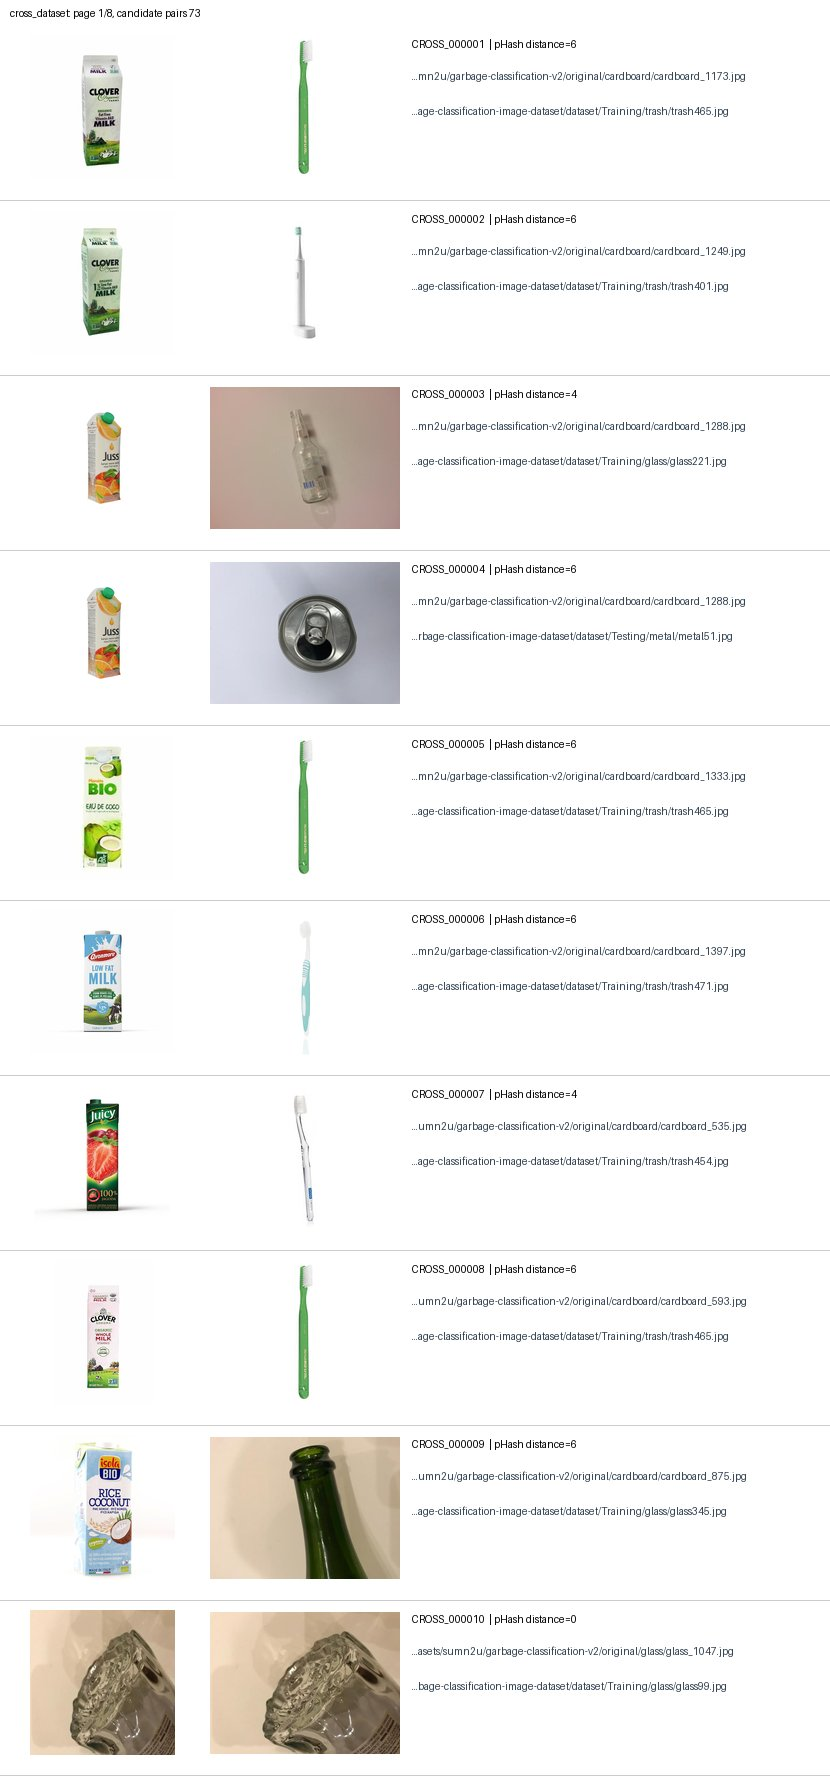

Example contact sheet: /kaggle/working/REMNET_Stage3_Section2_Verification/Section2_NearDuplicate_ContactSheets/within_external/within_external_0001.jpg


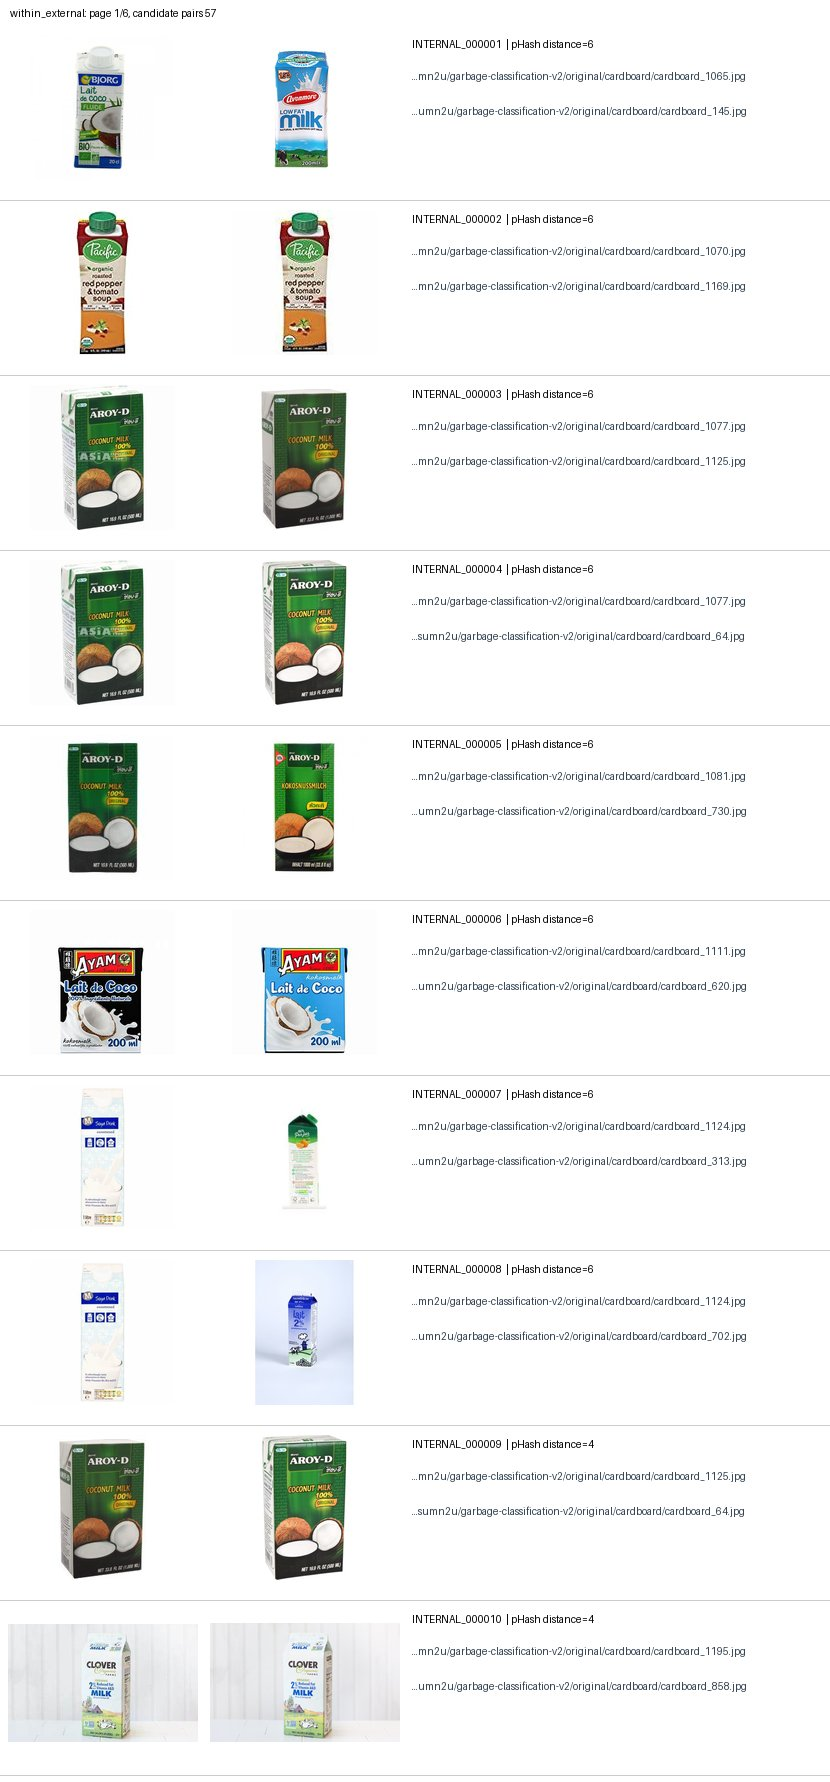

In [8]:
# 8 — Visual review contact sheets for EVERY manageable candidate pair; no silent truncation
CONTACT_ROOT=OUTPUT/'Section2_NearDuplicate_ContactSheets'
CONTACT_ROOT.mkdir(parents=True,exist_ok=True)

def thumbnail(path,size=(190,145)):
    try:
        with Image.open(path) as im:
            return ImageOps.pad(ImageOps.exif_transpose(im).convert('RGB'),size,method=Image.Resampling.LANCZOS,color='white')
    except Exception:
        return Image.new('RGB',size,'#ffdddd')

def safe_text(text,maxlen=69):
    s=str(text)
    return s if len(s)<=maxlen else '…'+s[-maxlen+1:]

def make_contact_sheets(pairs,label,path_left,path_right):
    if not pairs:
        return 0,False
    total=math.ceil(len(pairs)/CONTACT_PAIRS_PER_SHEET)
    overflow=total>MAX_CONTACT_SHEETS_PER_REVIEW
    dest=CONTACT_ROOT/label;dest.mkdir(parents=True,exist_ok=True)
    for page in range(min(total,MAX_CONTACT_SHEETS_PER_REVIEW)):
        chunk=pairs[page*CONTACT_PAIRS_PER_SHEET:(page+1)*CONTACT_PAIRS_PER_SHEET]
        canvas=Image.new('RGB',(830,32+len(chunk)*175),'white')
        dr=ImageDraw.Draw(canvas)
        dr.text((10,7),f'{label}: page {page+1}/{total}, candidate pairs {len(pairs)}',fill='black')
        for i,rec in enumerate(chunk):
            y=30+i*175
            left=Path(path_left(rec));right=Path(path_right(rec))
            canvas.paste(thumbnail(left),(8,y+5))
            canvas.paste(thumbnail(right),(210,y+5))
            dr.text((412,y+8),f"{rec['pair_id']}  | pHash distance={rec['phash_hamming_distance']}",fill='black')
            dr.text((412,y+40),safe_text(left),fill='#304050')
            dr.text((412,y+75),safe_text(right),fill='#304050')
            dr.line((0,y+170,830,y+170),fill='#cccccc')
        canvas.save(dest/f'{label}_{page+1:04d}.jpg',quality=85)
    return min(total,MAX_CONTACT_SHEETS_PER_REVIEW),overflow

cross_sheets,cross_sheet_overflow=make_contact_sheets(cross_pairs,'cross_dataset',
    lambda r:EXTERNAL_CLASS_ROOT/r['external_relative_path'],lambda r:r['original_image_path'])
internal_sheets,internal_sheet_overflow=make_contact_sheets(internal_pairs,'within_external',
    lambda r:EXTERNAL_CLASS_ROOT/r['image_a_relative_path'],lambda r:EXTERNAL_CLASS_ROOT/r['image_b_relative_path'])
print('Visual sheets created: cross=',cross_sheets,'within=',internal_sheets)
print('Contact-sheet review coverage complete:',not(cross_sheet_overflow or internal_sheet_overflow))

# Kaggle preview: show first sheet for each review type without dumping thousands of images.
try:
    from IPython.display import display
    for d in [CONTACT_ROOT/'cross_dataset', CONTACT_ROOT/'within_external']:
        candidates=sorted(d.glob('*.jpg')) if d.exists() else []
        if candidates:
            print('Example contact sheet:',candidates[0]); display(Image.open(candidates[0]))
except Exception as exc:
    print('Preview unavailable, but images were saved:',str(exc)[:150])

### 9 · Pixel-identical evidence, independent of pHash

The code computes decoded-pixel SHA-256 signatures to identify truly identical raster content despite differing file metadata or encodings. Any legacy review CSV files generated by this stage are **auxiliary evidence only**. They are **not required** for finalizing the automated-screened evaluation cohort. All candidate images remain excluded by the conservative selection rule.


In [9]:
# 9 — Bind each pHash candidate to the actual SHA-256 image bytes, then compute
# independent decoded-pixel identity evidence. No manual CSV editing/review step.
UTC=lambda:datetime.datetime.now(datetime.timezone.utc).isoformat()

def exact_pixels_digest(path):
    with Image.open(path) as im:
        rgb=ImageOps.exif_transpose(im).convert('RGB')
        h=hashlib.sha256()
        h.update(str(rgb.size).encode('utf-8'))
        h.update(rgb.tobytes())
        return h.hexdigest(),rgb.size

PIXEL_DIGEST_CACHE={}
def pixel_signature(path):
    path=str(path)
    if path not in PIXEL_DIGEST_CACHE:
        PIXEL_DIGEST_CACHE[path]=exact_pixels_digest(path)
    return PIXEL_DIGEST_CACHE[path]

def pair_pixel_identity(record,mode):
    if mode=='cross':
        a=EXTERNAL_CLASS_ROOT/record['external_relative_path']
        b=Path(record['original_image_path'])
    else:
        a=EXTERNAL_CLASS_ROOT/record['image_a_relative_path']
        b=EXTERNAL_CLASS_ROOT/record['image_b_relative_path']
    try:
        sa,wh_a=pixel_signature(a)
        sb,wh_b=pixel_signature(b)
        return sa==sb,('identical decoded RGB pixels at '+str(wh_a)) if sa==sb else ''
    except Exception as exc:
        raise RuntimeError(f'Pixel examination failed for {record["pair_id"]}: {exc}') from exc

external_sha_lookup={r['external_relative_path']:r['sha256'].lower() for r in external_records}
original_sha_lookup={str(r['path']):r['sha256'].lower() for r in original_records}
for pair in cross_pairs:
    pair['image_a_sha256']=external_sha_lookup[pair['external_relative_path']]
    pair['image_b_sha256']=original_sha_lookup[pair['original_image_path']]
for pair in internal_pairs:
    pair['image_a_sha256']=external_sha_lookup[pair['image_a_relative_path']]
    pair['image_b_sha256']=external_sha_lookup[pair['image_b_relative_path']]

# Candidate ledgers with immutable image signatures; no PENDING review workflow.
CROSS_REVIEW_ROWS=cross_pairs
WITHIN_REVIEW_ROWS=internal_pairs
write_csv(OUTPUT/'Section2_CrossDataset_pHash_Candidates_SHA256.csv',cross_pairs,
          CROSS_HEADERS+['image_a_sha256','image_b_sha256'])
write_csv(OUTPUT/'Section2_WithinExternal_pHash_Candidates_SHA256.csv',internal_pairs,
          INTERNAL_HEADERS+['image_a_sha256','image_b_sha256'])
print(f'Candidate pairs ready for automatic pixel examination: {len(cross_pairs)} cross + {len(internal_pairs)} within.')


Candidate pairs ready for automatic pixel examination: 73 cross + 57 within.


### 9A · Automated visual examination performed inside Kaggle

Every pHash candidate pair is opened and scored as image pixels: decoded-pixel identity, luminance SSIM, normalized RGB mean absolute error, luminance correlation and ORB/RANSAC geometric support when available. Evidence files include the paired images and enhanced difference map.

No human decisions are required. Algorithmic scores are diagnostic and not used to silently approve flagged images. The final cohort excludes **all** flagged images and is locked only after examination succeeds for every pair.


AUTOMATED VISUAL EXAMINATION COMPLETE: True
Pairs examined in Kaggle: cross 73, within 57, successful 130/130
Automated evidence classes: {'INDETERMINATE_CONSERVATIVELY_WITHHELD': 80, 'HIGH_CONFIDENCE_VISUAL_MATCH_NOT_HUMAN_VERIFIED': 50}
Evidence images: /kaggle/working/REMNET_Stage3_Section2_Verification/Section2_Automated_Visual_Evidence
No manual visual-review step is required. Every pHash-flagged image stays withheld from the automatically screened cohort.
Example image-by-image visual evidence: /kaggle/working/REMNET_Stage3_Section2_Verification/Section2_Automated_Visual_Evidence/Cross/CROSS_000001.jpg


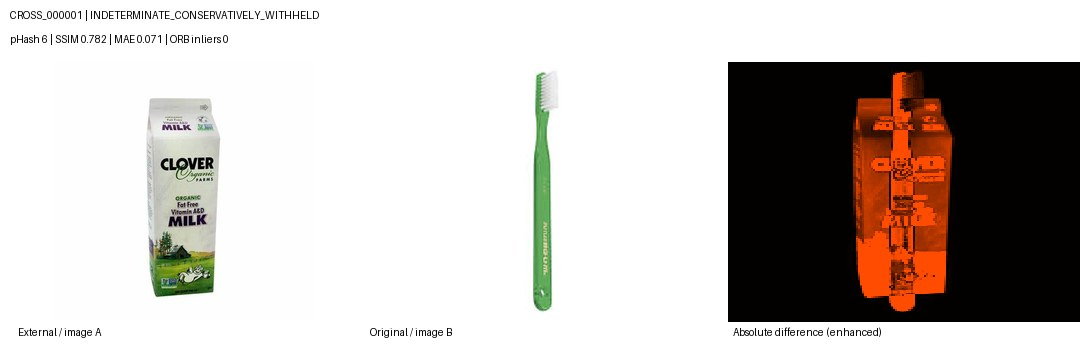

Example image-by-image visual evidence: /kaggle/working/REMNET_Stage3_Section2_Verification/Section2_Automated_Visual_Evidence/Within/INTERNAL_000001.jpg


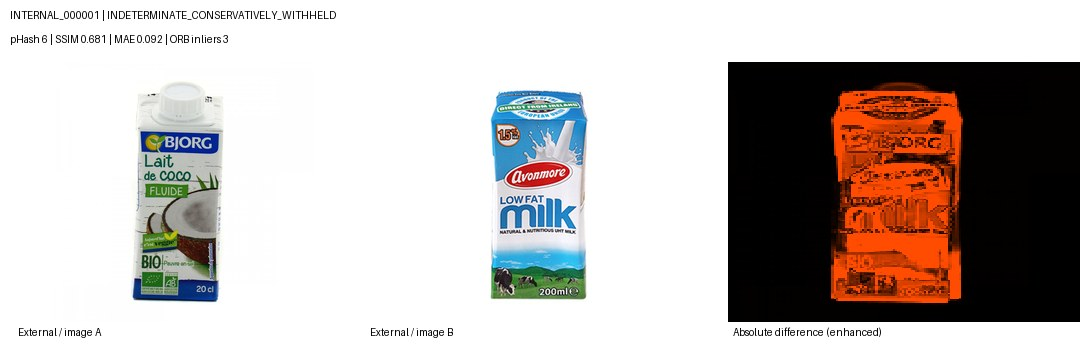

In [10]:
# 9A — AUTOMATED image-by-image visual examination INSIDE Kaggle (CPU only)
# Scores every candidate pair, writes transparent evidence, NEVER invents human review.
from scipy.ndimage import gaussian_filter
try:
    import cv2
    CV2_PRESENT=True
except ImportError:
    cv2=None
    CV2_PRESENT=False

AUTOVIS_DIR=OUTPUT/'Section2_Automated_Visual_Evidence'
AUTOVIS_DIR.mkdir(parents=True,exist_ok=True)
AUTO_VISUAL_SIZE=(160,160)
AUTO_ORB_SIZE=(384,384)
AUTOVIS_PIXEL_CACHE={}
AUTOVIS_ORB_CACHE={}
ORB_DETECTOR=cv2.ORB_create(nfeatures=1400,fastThreshold=10) if CV2_PRESENT else None


def normalized_image(path,size=AUTO_VISUAL_SIZE):
    key=(str(path),size)
    if key not in AUTOVIS_PIXEL_CACHE:
        with Image.open(path) as im:
            image=ImageOps.exif_transpose(im).convert('RGB').resize(size,Image.Resampling.LANCZOS)
            AUTOVIS_PIXEL_CACHE[key]=np.asarray(image,dtype=np.uint8)
    return AUTOVIS_PIXEL_CACHE[key]


def ssim_gray(a,b):
    # SSIM of 160x160 luminance; same geometric resize for both inputs.
    x=(0.299*a[:,:,0]+0.587*a[:,:,1]+0.114*a[:,:,2]).astype(np.float32)/255.0
    y=(0.299*b[:,:,0]+0.587*b[:,:,1]+0.114*b[:,:,2]).astype(np.float32)/255.0
    ux=gaussian_filter(x,sigma=1.5);uy=gaussian_filter(y,sigma=1.5)
    vx=np.maximum(gaussian_filter(x*x,1.5)-ux*ux,0)
    vy=np.maximum(gaussian_filter(y*y,1.5)-uy*uy,0)
    cov=gaussian_filter(x*y,1.5)-ux*uy
    C1=0.01**2;C2=0.03**2
    m=((2*ux*uy+C1)*(2*cov+C2))/((ux*ux+uy*uy+C1)*(vx+vy+C2))
    return float(np.clip(m.mean(),-1,1))


def gray_corr(a,b):
    xa=(.299*a[:,:,0]+.587*a[:,:,1]+.114*a[:,:,2]).ravel().astype(np.float32)
    xb=(.299*b[:,:,0]+.587*b[:,:,1]+.114*b[:,:,2]).ravel().astype(np.float32)
    xa-=xa.mean();xb-=xb.mean()
    den=np.sqrt(float(np.dot(xa,xa))*float(np.dot(xb,xb)))
    return float(np.dot(xa,xb)/den) if den>1e-10 else 0.0


def orb_desc(path):
    path=str(path)
    if path not in AUTOVIS_ORB_CACHE:
        ar=normalized_image(path,AUTO_ORB_SIZE)
        gray=cv2.cvtColor(ar,cv2.COLOR_RGB2GRAY)
        keypoints,desc=ORB_DETECTOR.detectAndCompute(gray,None)
        AUTOVIS_ORB_CACHE[path]=(keypoints,desc)
    return AUTOVIS_ORB_CACHE[path]


def orb_geometric_support(a,b):
    if not CV2_PRESENT:
        return {'orb_good_matches':None,'orb_ransac_inliers':None,'orb_inlier_fraction':None}
    ka,da=orb_desc(a);kb,db=orb_desc(b)
    if da is None or db is None or len(da)<4 or len(db)<4:
        return {'orb_good_matches':0,'orb_ransac_inliers':0,'orb_inlier_fraction':0.0}
    matches=cv2.BFMatcher(cv2.NORM_HAMMING,crossCheck=False).knnMatch(da,db,k=2)
    good=[m for pair in matches if len(pair)==2 for m,n in [pair] if m.distance<.73*n.distance]
    support=0
    if len(good)>=8:
        pa=np.float32([ka[m.queryIdx].pt for m in good]).reshape(-1,1,2)
        pb=np.float32([kb[m.trainIdx].pt for m in good]).reshape(-1,1,2)
        try:
            _H,mask=cv2.findHomography(pa,pb,cv2.RANSAC,4.0)
            support=int(mask.sum()) if mask is not None else 0
        except cv2.error:
            support=0
    return {'orb_good_matches':len(good),
            'orb_ransac_inliers':support,
            'orb_inlier_fraction':round(support/len(good),5) if good else 0.0}


def pair_sources(rec,mode):
    if mode=='cross':
        return EXTERNAL_CLASS_ROOT/rec['external_relative_path'],Path(rec['original_image_path'])
    return EXTERNAL_CLASS_ROOT/rec['image_a_relative_path'],EXTERNAL_CLASS_ROOT/rec['image_b_relative_path']


def pair_visual_measure(rec,mode):
    a_path,b_path=pair_sources(rec,mode)
    record={'pair_id':rec['pair_id'],'pair_type':mode,
            'image_a_path':str(a_path),'image_b_path':str(b_path),
            'image_a_sha256':rec['image_a_sha256'],
            'image_b_sha256':rec['image_b_sha256'],
            'phash_hamming_distance':int(rec['phash_hamming_distance']),
            'reference_class_a':rec['external_class'] if mode=='cross' else rec['image_a_class'],
            'reference_class_b':rec['original_class'] if mode=='cross' else rec['image_b_class'],
            'assessment_origin':'AUTOMATED_IMAGE_PIXEL_ANALYSIS_IN_KAGGLE',
            'automated_visual_assessment':'INDETERMINATE',
            'retained_in_conservative_cohort':False,
            'analysis_error':'', 'image_evidence_file':''}
    try:
        ar=normalized_image(a_path);br=normalized_image(b_path)
        exact,exact_note=pair_pixel_identity(rec,mode)
        ssim=ssim_gray(ar,br)
        mae=float(np.abs(ar.astype(np.float32)-br.astype(np.float32)).mean()/255.)
        corr=gray_corr(ar,br)
        orb=orb_geometric_support(a_path,b_path)
        inliers=orb['orb_ransac_inliers'] or 0
        fraction=orb['orb_inlier_fraction'] or 0
        if exact:
            decision='PIXEL_EQUIVALENT_CONFIRMED'
        elif (ssim>=0.975 and mae<=0.055) or (CV2_PRESENT and inliers>=22 and fraction>=.55 and ssim>=.69):
            decision='HIGH_CONFIDENCE_VISUAL_MATCH_NOT_HUMAN_VERIFIED'
        elif (ssim<.42 and corr<.38 and mae>.15 and (not CV2_PRESENT or inliers<=3)):
            decision='LIKELY_DIFFERENT_NOT_HUMAN_VERIFIED'
        else:
            decision='INDETERMINATE_CONSERVATIVELY_WITHHELD'
        record.update({'decoded_pixels_identical':bool(exact),
                       'pixel_identity_evidence':exact_note,
                       'ssim_luminance_160':round(ssim,6),
                       'mae_rgb_160':round(mae,6),
                       'luminance_correlation_160':round(corr,6),
                       **orb,'automated_visual_assessment':decision})
        # Save side-by-side original images and difference heatmap for independently examining EVERY pair.
        cell=(352,260)
        a_view=thumbnail(a_path,cell);b_view=thumbnail(b_path,cell)
        d=np.abs(ar.astype(np.int16)-br.astype(np.int16)).mean(axis=2)
        d=np.clip(d*3,0,255).astype(np.uint8)
        heat=np.zeros((d.shape[0],d.shape[1],3),dtype=np.uint8)
        heat[:,:,0]=d
        heat[:,:,1]=(d.astype(np.float32)*.30).astype(np.uint8)
        heat_img=Image.fromarray(heat,'RGB').resize(cell,Image.Resampling.NEAREST)
        canvas=Image.new('RGB',(1080,350),'white')
        for i,img in enumerate((a_view,b_view,heat_img)):
            canvas.paste(img,(8+360*i,62))
        dr=ImageDraw.Draw(canvas)
        dr.text((10,9),rec['pair_id']+' | '+decision[:65],fill='black')
        dr.text((10,33),f'pHash {rec["phash_hamming_distance"]} | SSIM {ssim:.3f} | MAE {mae:.3f} | ORB inliers {inliers}',fill='black')
        dr.text((18,326),'External / image A',fill='black')
        dr.text((370,326),'Original / image B' if mode=='cross' else 'External / image B',fill='black')
        dr.text((733,326),'Absolute difference (enhanced)',fill='black')
        subdir=AUTOVIS_DIR/('Cross' if mode=='cross' else 'Within')
        subdir.mkdir(parents=True,exist_ok=True)
        visual_file=subdir/(rec['pair_id']+'.jpg')
        canvas.save(visual_file,quality=88)
        record['image_evidence_file']=str(visual_file.relative_to(OUTPUT))
    except Exception as exc:
        record['automated_visual_assessment']='ERROR_UNRESOLVED'
        record['analysis_error']=f'{type(exc).__name__}: {exc}'[:350]
    return record

AUTO_CROSS=[pair_visual_measure(rec,'cross') for rec in CROSS_REVIEW_ROWS]
AUTO_WITHIN=[pair_visual_measure(rec,'within') for rec in WITHIN_REVIEW_ROWS]
AUTO_ALL=AUTO_CROSS+AUTO_WITHIN
AUTO_FIELDS=['pair_id','pair_type','image_a_path','image_b_path','image_a_sha256','image_b_sha256',
             'reference_class_a','reference_class_b','phash_hamming_distance',
             'decoded_pixels_identical','pixel_identity_evidence','ssim_luminance_160',
             'mae_rgb_160','luminance_correlation_160','orb_good_matches','orb_ransac_inliers',
             'orb_inlier_fraction','automated_visual_assessment','assessment_origin',
             'retained_in_conservative_cohort','image_evidence_file','analysis_error']
write_csv(OUTPUT/'Section2_Automated_Visual_CrossDataset_Pairwise.csv',AUTO_CROSS,AUTO_FIELDS)
write_csv(OUTPUT/'Section2_Automated_Visual_WithinExternal_Pairwise.csv',AUTO_WITHIN,AUTO_FIELDS)
write_csv(OUTPUT/'Section2_Automated_Visual_All_Pairs.csv',AUTO_ALL,AUTO_FIELDS)
AUTO_DONE=sum(not r['analysis_error'] for r in AUTO_ALL)
AUTOMATED_VISUAL_ANALYSIS_COMPLETE=(AUTO_DONE==len(AUTO_ALL) and not (cross_sheet_overflow or internal_sheet_overflow))
AUTOVISUAL_SUMMARY={
    'automated_visual_comparison_complete':AUTOMATED_VISUAL_ANALYSIS_COMPLETE,
    'automated_visual_pairs_processed_successfully':AUTO_DONE,
    'automated_visual_pairs_total':len(AUTO_ALL),
    'automated_visual_cross_pairs':len(AUTO_CROSS),
    'automated_visual_within_pairs':len(AUTO_WITHIN),
    'automated_visual_assessment_distribution':dict(Counter(r['automated_visual_assessment'] for r in AUTO_ALL)),
    'human_review_required_for_automated_protocol':False,
    'automated_visual_methods':'Decoded pixels, SSIM, RGB MAE, luminance correlation, and ORB-RANSAC (if available); side-by-side/difference-map evidence for each pair',
    'automated_visual_all_phash_candidates_conservatively_withheld':True,
    'automated_visual_limitation':'Algorithms cannot substitute for human visual adjudication or certify dataset collection independence.'}
(OUTPUT/'Section2_Automated_Visual_Examination_Summary.json').write_text(json.dumps(AUTOVISUAL_SUMMARY,indent=2),encoding='utf-8')
print('AUTOMATED VISUAL EXAMINATION COMPLETE:',AUTOMATED_VISUAL_ANALYSIS_COMPLETE)
print(f'Pairs examined in Kaggle: cross {len(AUTO_CROSS)}, within {len(AUTO_WITHIN)}, successful {AUTO_DONE}/{len(AUTO_ALL)}')
print('Automated evidence classes:',AUTOVISUAL_SUMMARY['automated_visual_assessment_distribution'])
print('Evidence images:',AUTOVIS_DIR)
print('No manual visual-review step is required. Every pHash-flagged image stays withheld from the automatically screened cohort.')
try:
    from IPython.display import display
    for group in ('Cross','Within'):
        previews=sorted((AUTOVIS_DIR/group).glob('*.jpg')) if (AUTOVIS_DIR/group).is_dir() else []
        if previews:
            print('Example image-by-image visual evidence:',previews[0]);display(Image.open(previews[0]))
except Exception as exc:
    print('Preview display unavailable:',exc)


In [11]:
# 10 — Verify Stage 2 output indices; document source, version, license notices, and provenance.
# The Stage 2 EfficientNet and REMNET notebooks use torchvision.datasets.ImageFolder.
# ImageFolder sorts the six class folder names alphabetically; it does NOT use the
# ten-class external ImageFolder indices.
STAGE2_RECORDED_CLASSES=tuple(sorted(KEEP))
ORIGINAL_FOLDER_CLASSES=tuple(sorted(original_directories)) if ORIGINAL_AVAILABLE else ()
CLASS_MAPPING_VERIFIED=(ORIGINAL_AVAILABLE and STAGE2_RECORDED_CLASSES==KEEP
                        and ORIGINAL_FOLDER_CLASSES==KEEP and MANIFEST_VALID
                        and set(r['class'] for r in stage2_manifest)==set(KEEP))
class_mapping=[{'external_folder_class':name,'stage2_trained_class':name,
    'stage2_output_index':i,'stage2_class_to_idx':f'{name}:{i}',
    'stage2_source_rule':'torchvision ImageFolder sorted folder names (six classes)',
    'class_mapping_verified':CLASS_MAPPING_VERIFIED,
    'evidence':'Stage 2 ImageFolder implementation + locked split manifest classes + public original class folders'}
    for i,name in enumerate(KEEP)]
write_csv(OUTPUT/'Section2_Six_Class_Mapping.csv',class_mapping,
    ['external_folder_class','stage2_trained_class','stage2_output_index','stage2_class_to_idx',
     'stage2_source_rule','class_mapping_verified','evidence'])

# Actual image-byte inventory fingerprint (NOT a fingerprint of the Kaggle webpage).
image_snapshot=hashlib.sha256()
for item in sorted(external_records,key=lambda r:r['external_relative_path']):
    image_snapshot.update((item['external_relative_path']+'\t'+item['sha256']+'\n').encode('utf-8'))
EXTERNAL_INVENTORY_SHA256=image_snapshot.hexdigest()

# Public source notices have DIFFERENT license terms. Document both; do not invent
# resolution or silently treat a GitHub CODE license as the dataset's license.
DATASET_PROVENANCE={
  'external_name':'Garbage Classification V2 / Garbage Dataset (GD)',
  'external_creator':'Suman Kunwar (sumn2u)',
  'external_source_url':'https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2',
  'external_requested_version':'12',
  'external_resolved_version':EXTERNAL_VERSION_ACTUAL,
  'external_download_method':EXTERNAL_LOAD_METHOD,
  'external_resolved_root':str(EXTERNAL_MOUNT),
  'external_class_root':str(EXTERNAL_CLASS_ROOT),
  'original_public_dataset_url':'https://www.kaggle.com/datasets/saumyamohandas/garbage-classification-image-dataset',
  'original_public_download_method':ORIGINAL_LOAD_METHOD,
  'original_public_dataset_root':str(ORIGINAL_MOUNT),
  'locked_stage2_manifest_source':str(MANIFEST_PATH) if MANIFEST_PATH else None,
  'locked_stage2_manifest_records':len(stage2_manifest) if MANIFEST_VALID else None,
  'license_recorded_kaggle':'MIT — Kaggle source listing; applicability should be checked against exact v12 archive',
  'license_recorded_creator_site':'CC BY-SA 4.0 — https://www.dwaste.live/dataset/',
  'license_reconciliation':'UNRESOLVED SOURCE CONFLICT; both notices documented, do not claim legal resolution',
  'citation_primary':'Kunwar, S. (2026). The Garbage Dataset (GD): A Multi-Class Image Benchmark for Automated Waste Segregation. https://doi.org/10.5753/jbcs.2026.7774',
  'citation_repository':'Kunwar, S. (2026). The Garbage Dataset (GD): A Multi-Class Image Benchmark for Automated Waste Segregation. Zenodo. https://doi.org/10.5281/zenodo.18841812',
  'creator_page':'https://www.dwaste.live/dataset/',
  'downloaded_at_utc':UTC(),
  'external_image_inventory_sha256':EXTERNAL_INVENTORY_SHA256,
  'ten_class_counts':external_counts,
  'ten_class_total':external_total,
  'selected_six_class_total':selected_total,
  'excluded_four_class_total':excluded_total,
  'sha256_overlap_locked_stage2_by_partition':dict(stage2_match_counts),
  'sha256_overlap_full_public_reference_count':sum(original_public_overlap_counts.values()),
  'pHash_cross_candidate_pairs':len(cross_pairs),
  'pHash_within_external_candidate_pairs':len(internal_pairs),
  'pHash_threshold_hamming':PHASH_THRESHOLD,
  'class_mapping_verified':CLASS_MAPPING_VERIFIED,
  'scope_limitation':'Six-class screened nonoverlapping subset; common-source provenance may remain',
  'same_subset_rule':'Only locked manifest (same SHA-256 fingerprint) for four models/five seeds'
}
(OUTPUT/'Section2_Source_License_Citation_Version_Download_Details.json').write_text(
   json.dumps(DATASET_PROVENANCE,indent=2,ensure_ascii=False),encoding='utf-8')
print('Stage 2 class mapping verified:',CLASS_MAPPING_VERIFIED)
print('External V2 version recorded:',EXTERNAL_VERSION_ACTUAL)
print('Kaggle license notice: MIT; creator site notice: CC BY-SA 4.0 (conflict documented)')

Stage 2 class mapping verified: True
External V2 version recorded: 12
Kaggle license notice: MIT; creator site notice: CC BY-SA 4.0 (conflict documented)


In [12]:
# 11 — Fully automatic protocol finalization. No human-review CSV decisions are needed.
# All pHash-alerted image records are withheld from the definitive automated-screened cohort.
# The final manifest is generated ONLY after screening+image-examination integrity checks.

MANIFEST_HEADERS = [
 'external_relative_path','external_absolute_path','class','output_index','sha256',
 'exact_stage2_partitions','exact_stage2_source_paths','exact_public_reference_paths',
 'exact_internal_duplicate_count','exact_internal_conflicting_labels','decodable','decode_error',
 'phash_hex','stage2_label_conflict','public_reference_label_conflict','base_status',
 'final_status','exclusion_reason'
]


def finalize_automated_screening(verbose=True):
    old_manual_verified=OUTPUT/'Section2_Final_Six_Class_Locked_Manifest.csv'
    if old_manual_verified.is_file():old_manual_verified.unlink()  # obsolete output from older manual protocol
    cross_flagged={p['external_relative_path'] for p in cross_pairs}
    within_flagged={p['image_a_relative_path'] for p in internal_pairs}
    within_flagged.update(p['image_b_relative_path'] for p in internal_pairs)
    flagged=cross_flagged|within_flagged

    for record in external_records:
        sha=record['sha256'].lower()
        locked_labels={m['class'] for m in stage2_by_sha.get(sha,[])}
        public_labels={m['class'] for m in orig_by_sha.get(sha,[])}
        record['stage2_label_conflict']=bool(locked_labels and record['class'] not in locked_labels)
        record['public_reference_label_conflict']=bool(public_labels and record['class'] not in public_labels)
        record['output_index']=KEEP.index(record['class'])
        record['phash_hex']=f"{record['phash_int']:016x}" if 'phash_int' in record else ''
        if record['base_status'].startswith('EXCLUDE_'):
            record['final_status']=record['base_status']
            record['exclusion_reason']='Exact overlap, exact internal duplicate, conflicting labels, unreadable or hash failure; see base_status'
        elif record['external_relative_path'] in flagged:
            record['final_status']='EXCLUDE_PHASH_ALERT_CONSERVATIVE'
            record['exclusion_reason']='pHash candidate; withheld conservatively (NOT established as a duplicate)'
        elif record['base_status']=='CANDIDATE_PHASH_SCREEN' and 'phash_int' in record:
            record['final_status']='INCLUDE_AUTOMATED_SCREENED'
            record['exclusion_reason']=''
        else:
            record['final_status']='EXCLUDE_UNRESOLVED_IMAGE_INTEGRITY'
            record['exclusion_reason']='Unexpected image integrity/status condition'

    eligible=[r for r in external_records if r['final_status']=='INCLUDE_AUTOMATED_SCREENED']
    excluded=[r for r in external_records if r['final_status'].startswith('EXCLUDE_')]
    withheld=[r for r in external_records if r['final_status']=='EXCLUDE_PHASH_ALERT_CONSERVATIVE']
    counts=Counter(r['class'] for r in eligible)

    write_csv(OUTPUT/'Section2_External_Complete_Manifest.csv',external_records,MANIFEST_HEADERS)
    write_csv(OUTPUT/'Section2_Exclusions.csv',excluded,MANIFEST_HEADERS)
    write_csv(OUTPUT/'Section2_Conservative_Withheld_pHash_Candidates.csv',withheld,MANIFEST_HEADERS)
    write_csv(OUTPUT/'Section2_Provisional_Eligible_Manifest.csv',eligible,MANIFEST_HEADERS)
    conflict_rows=[r for r in external_records if r.get('stage2_label_conflict') or
                    r.get('public_reference_label_conflict') or r.get('exact_internal_conflicting_labels')]
    write_csv(OUTPUT/'Section2_Exact_Label_Conflicts.csv',conflict_rows,MANIFEST_HEADERS)
    write_csv(OUTPUT/'Section2_Final_Automated_Six_Class_Counts.csv',
              [{'class':c,'images':counts[c],'output_index':KEEP.index(c)} for c in KEEP],
              ['class','images','output_index'])

    blockers=[]
    if not MANIFEST_VALID:blockers.append('Locked Stage 2 manifest invalid or missing')
    if MANIFEST_VALID and stage2_unresolved:blockers.append(f'{len(stage2_unresolved)} Stage 2 image hashes unresolved')
    if not ORIGINAL_AVAILABLE:blockers.append('Original public six-class image roots incomplete')
    if not STAGE2_PHASH_COMPLETE:blockers.append('Original Stage 2 pHash incomplete')
    if not ORIGINAL_REFERENCE_PHASH_COMPLETE:blockers.append('Public original reference pHash incomplete')
    if not EXTERNAL_PHASH_COMPLETE:blockers.append('External pHash incomplete')
    if not AUTOMATED_VISUAL_ANALYSIS_COMPLETE:
        blockers.append(f'Automated visual examination incomplete: {AUTO_DONE}/{len(AUTO_ALL)} pairs')
    if not CLASS_MAPPING_VERIFIED:blockers.append('Original Stage 2 class-index mapping unverified')
    if EXTERNAL_VERSION_ACTUAL!=EXTERNAL_DATASET_VERSION:blockers.append('External V2 snapshot version not verified as 12')
    if set(counts)!=set(KEEP) or any(counts[c]==0 for c in KEEP):
        blockers.append('Final cohort missing a required class')
    if any(r['external_relative_path'] in flagged for r in eligible):
        blockers.append('pHash-flagged image in final cohort')
    if len({r['external_relative_path'] for r in eligible})!=len(eligible):
        blockers.append('Duplicate external-relative paths in cohort')
    if len({r['sha256'] for r in eligible})!=len(eligible):
        blockers.append('Identical SHA-256 image records retained in cohort')
    if any(r['sha256'].lower() in orig_by_sha or r['sha256'].lower() in stage2_by_sha for r in eligible):
        blockers.append('Exact original-source SHA-256 overlap retained in cohort')
    if any(r['base_status']!='CANDIDATE_PHASH_SCREEN' or 'phash_int' not in r for r in eligible):
        blockers.append('Incomplete image integrity evidence in cohort')
    if len(eligible)+len(excluded)!=len(external_records):
        blockers.append('Manifest exclusion/inclusion accounting mismatch')
    if cross_sheet_overflow or internal_sheet_overflow:
        blockers.append('Candidate contact-sheet evidence coverage incomplete')
    if len(AUTO_CROSS)!=len(cross_pairs) or len(AUTO_WITHIN)!=len(internal_pairs):
        blockers.append('Automated candidate-pair count mismatch')

    locked=(len(blockers)==0)
    final_path=OUTPUT/'Section2_Final_Automated_Screened_Six_Class_Manifest.csv'
    legacy_path=OUTPUT/'Section2_Conservative_Frozen_Six_Class_Manifest.csv'
    if locked:
        write_csv(final_path,eligible,MANIFEST_HEADERS)
        write_csv(legacy_path,eligible,MANIFEST_HEADERS)   # backwards-compatible path
    else:
        for p in (final_path,legacy_path):
            if p.is_file():p.unlink()

    manifest_fingerprint=hashlib.sha256()
    for r in sorted(eligible,key=lambda x:x['external_relative_path']):
        manifest_fingerprint.update((r['external_relative_path']+'\t'+r['sha256']+'\t'+
                                     str(r['output_index'])+'\n').encode('utf-8'))
    digest=manifest_fingerprint.hexdigest() if locked else None
    automation={
        'automated_image_by_image_visual_examination_complete':AUTOMATED_VISUAL_ANALYSIS_COMPLETE,
        'image_pairs_processed':AUTO_DONE,'image_pairs_total':len(AUTO_ALL),
        'human_visual_review_required':False,
        'pHash_candidate_images_withheld':len(withheld),
        'conservative_screened_subset_frozen':locked,
        'final_automated_screened_subset_locked':locked,
        'final_manifest_file':final_path.name if locked else None,
        'manifest_fingerprint_sha256':digest,
        'image_count':len(eligible),
        'class_counts':dict(counts),
        'reason_for_withholding':'All pHash-alerted images excluded regardless of algorithmic similarity decision; suspected duplicates not asserted as confirmed',
        'method_limitations':'Automated visual screening is not human adjudication; exact collection provenance independence is not demonstrated by image matching alone.',
        'blockers':blockers
    }
    (OUTPUT/'Section2_Automated_Protocol_Freeze_Evidence.json').write_text(
        json.dumps(automation,indent=2,ensure_ascii=False),encoding='utf-8')
    summary={**DATASET_PROVENANCE,**AUTOVISUAL_SUMMARY,**automation,
        'original_reference_images':len(original_records),
        'stage2_partition_image_counts':dict(Counter(r['split'] for r in stage2_manifest)) if MANIFEST_VALID else None,
        'stage2_sha256_overlap_counts_by_partition':dict(stage2_match_counts),
        'full_public_original_exact_overlap_images':sum(original_public_overlap_counts.values()),
        'external_six_class_candidate_count':selected_total,
        'external_four_class_excluded_count':excluded_total,
        'after_exact_filtering_count':len(eligible_for_phash),
        'automated_visual_cross_pair_count':len(AUTO_CROSS),
        'automated_visual_within_pair_count':len(AUTO_WITHIN),
        'exclusion_status_counts':dict(Counter(r['final_status'] for r in excluded)),
        'source_license_conflict_disclosed':True,
        'classification_models_must_share_exact_manifest':True,
        'audit_completed_at_utc':UTC()
    }
    (OUTPUT/'Section2_Verification_Summary.json').write_text(
        json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')
    report=[
        'REMNET STAGE 3 SECTION 2 — FULLY AUTOMATED DATASET SCREENING (NO MANUAL REVIEW)',
        f'Kaggle V2: requested {EXTERNAL_DATASET_VERSION}, resolved {EXTERNAL_VERSION_ACTUAL}; {EXTERNAL_LOAD_METHOD}',
        f'External total images: {external_total}; six-class candidates: {selected_total}; other four classes: {excluded_total}',
        f'Original public images: {len(original_records)}; original locked split manifest valid: {MANIFEST_VALID}',
        f'Stage 2 SHA-256 overlaps by split: {dict(stage2_match_counts)}',
        f'Full original public SHA-256 overlaps: {sum(original_public_overlap_counts.values())}',
        f'pHash candidate pairs: cross {len(cross_pairs)}; within external {len(internal_pairs)}',
        f'AUTOMATED VISUAL EXAMINATION COMPLETE: {AUTOMATED_VISUAL_ANALYSIS_COMPLETE} ({AUTO_DONE}/{len(AUTO_ALL)} pairs)',
        f'Original Stage 2 pHash complete: {STAGE2_PHASH_COMPLETE}',
        f'Stage 2 class-to-index verified: {CLASS_MAPPING_VERIFIED}',
        f'pHash-flagged external images withheld: {len(withheld)}',
        f'FINAL AUTOMATED-SCREENED SUBSET LOCKED: {locked}',
        f'Final automated-screened subset images: {len(eligible)}',
        f'Final manifest: {final_path.name if locked else "NOT WRITTEN"}',
        f'Manifest SHA-256 fingerprint: {digest if locked else "NOT AVAILABLE"}',
        'HUMAN REVIEW REQUIRED: NO (automated conservative protocol). No human visual verification claimed.',
        'LICENSE: MIT notice vs CC BY-SA 4.0 notice; discrepancy recorded, not legally resolved.',
        'CAVEAT: Candidate images are withheld, not automatically classified as confirmed duplicates.',
        'BLOCKERS: '+('; '.join(blockers) if blockers else 'None'),
        'No training, model inference, CodeCarbon monitoring, or changes to original image files.'
    ]
    (OUTPUT/'Section2_Verification_Report.txt').write_text('\n'.join(report)+'\n',encoding='utf-8')
    archive=OUTPUT/'REMNET_Stage3_Section2_Audit_Outputs.zip'
    with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED,compresslevel=5) as z:
        for p in sorted(OUTPUT.rglob('*')):
            if p.is_file() and p!=archive and not (
                p.name.endswith('_Review_COMPLETED.csv') or p.name.endswith('_Review_TEMPLATE.csv')
                or p.name=='Section2_Confirmed_Internal_Label_Conflicts.csv'
                or p.name=='Section2_Conservative_Freeze_Evidence.json'):
                z.write(p,p.relative_to(OUTPUT))
    if verbose:
        print('\n'.join(report))
        print('Audit ZIP:',archive)
    return summary

SUMMARY_CURRENT=finalize_automated_screening(verbose=True)


REMNET STAGE 3 SECTION 2 — FULLY AUTOMATED DATASET SCREENING (NO MANUAL REVIEW)
Kaggle V2: requested 12, resolved 12; kagglehub auto-download
External total images: 12259; six-class candidates: 7463; other four classes: 4796
Original public images: 2972; original locked split manifest valid: True
Stage 2 SHA-256 overlaps by split: {'Training': 1595, 'Testing': 401, 'Validation': 384}
Full original public SHA-256 overlaps: 2386
pHash candidate pairs: cross 73; within external 57
AUTOMATED VISUAL EXAMINATION COMPLETE: True (130/130 pairs)
Original Stage 2 pHash complete: True
Stage 2 class-to-index verified: True
pHash-flagged external images withheld: 146
FINAL AUTOMATED-SCREENED SUBSET LOCKED: True
Final automated-screened subset images: 4931
Final manifest: Section2_Final_Automated_Screened_Six_Class_Manifest.csv
Manifest SHA-256 fingerprint: 0761bdca0f92aea4efd8e5945e2954bf3d6958f41644e8699766839047ddd9be
HUMAN REVIEW REQUIRED: NO (automated conservative protocol). No human visual ve

## Outputs and scientific reporting

**No human visual-review step is required** under this conservative automated screening protocol. Kaggle computes all checks and makes the final cohort reproducibly identifiable by its manifest fingerprint.

- `Section2_Final_Automated_Screened_Six_Class_Manifest.csv` — **single frozen six-class image list** for all four models and all seeds, written only when automated checks pass.
- `Section2_External_Complete_Manifest.csv` — per-image labels, SHA-256/pHash, class index and exclusion status for every selected V2 candidate.
- `Section2_Exclusions.csv` — exact overlaps, within-V2 copies, unreadables and pHash alerts, with reasons.
- `Section2_Automated_Visual_All_Pairs.csv`, evidence JPEGs and `Section2_Automated_Visual_Examination_Summary.json` — complete image-by-image automated comparisons of every pHash pair.
- `Section2_Six_Class_Mapping.csv` — original Stage 2 trained six-class output indices.
- `Section2_Source_License_Citation_Version_Download_Details.json` — source metadata and unresolved license discrepancy.
- `Section2_Verification_Report.txt`, `Section2_Verification_Summary.json`, and `REMNET_Stage3_Section2_Audit_Outputs.zip` — final audit outputs.

**Report in the manuscript:** *Following SHA-256 comparisons with the locked Stage 2 partitions and original public source, all remaining pHash candidate pairs underwent automated image-level structural screening. All images involved in a pHash alert were conservatively excluded, without asserting that they were confirmed duplicates. The resulting fixed six-class evaluation cohort was used without modification for all model configurations.*

Do **not** write that images were human-verified or that independent collection provenance was established. The resulting image count is computed by Kaggle, not hard-coded.
